# Sea Level Rise Data

This notebook prepares the sea level rise projections for the sea level rise model (thesis Section 4.4 and Appendix A4).

The data are the KNMI23 projections of sea level rise along the Dutch coast: percentiles for every year 1995-2100 under three emission scenarios (SSP1-2.6, SSP2-4.5, SSP5-8.5), plus a few percentiles in 2150 and 2300. They are processed in three steps (`source/data.py`):

1. **Extrapolation** (`extrapolate_quantiles`): a quadratic trend per scenario and percentile extends the data to 2300.
2. **Distribution fit** (`get_scenario_quantile_fn`): a Pearson type IV distribution is fitted to the percentiles of each scenario and year. It fits the right-skewed data better than the normal distribution.
3. **Aggregation** (`get_aggregated_quantile_fn`): the scenario distributions are combined into a weighted mixture with weights $w = (0.25, 0.5, 0.25)$. The result is the quantile function $Q_t(p)$ used by the lattice.

The Pearson type IV distribution is evaluated with the R package `PearsonDS` (see the README).

In [1]:
from source.data import (
    extrapolate_quantiles,
    get_aggregated_quantile_fn,
    load_data,
    plot_aggregated_quantile_fn,
    plot_continuous_quantile_fns,
    plot_data,
    plot_data_against_all_distributions,
    plot_data_against_best_fitting_distribution,
    plot_data_against_distribution,
    plot_extrapolation_validation,
    plot_fan_charts,
    plot_uncertainty_band_aggregation_rule,
)

start_year, end_year = 2025, 2150

## Data

`load_data()` returns a nested dict: `q, p = data[year][scenario]` gives the quantiles `q` [m] at the probability levels `p`. The distributions are right-skewed, and SSP2-4.5 lies within the range spanned by SSP1-2.6 and SSP5-8.5.

In [8]:
data = load_data()
q, p = data[2100]["ssp585"]
print("Cumulative probability levels:", p)
print("Quantiles in 2100 (SSP5-8.5) [m]:", q)

Cumulative probability levels: [0.01 0.05 0.1  0.17 0.2  0.5  0.8  0.83 0.9  0.95 0.99]
Quantiles in 2100 (SSP5-8.5) [m]: [0.5079316  0.59038879 0.63645011 0.67960296 0.69493859 0.82026178
 0.99718564 1.02887904 1.12735615 1.23955309 1.94537853]


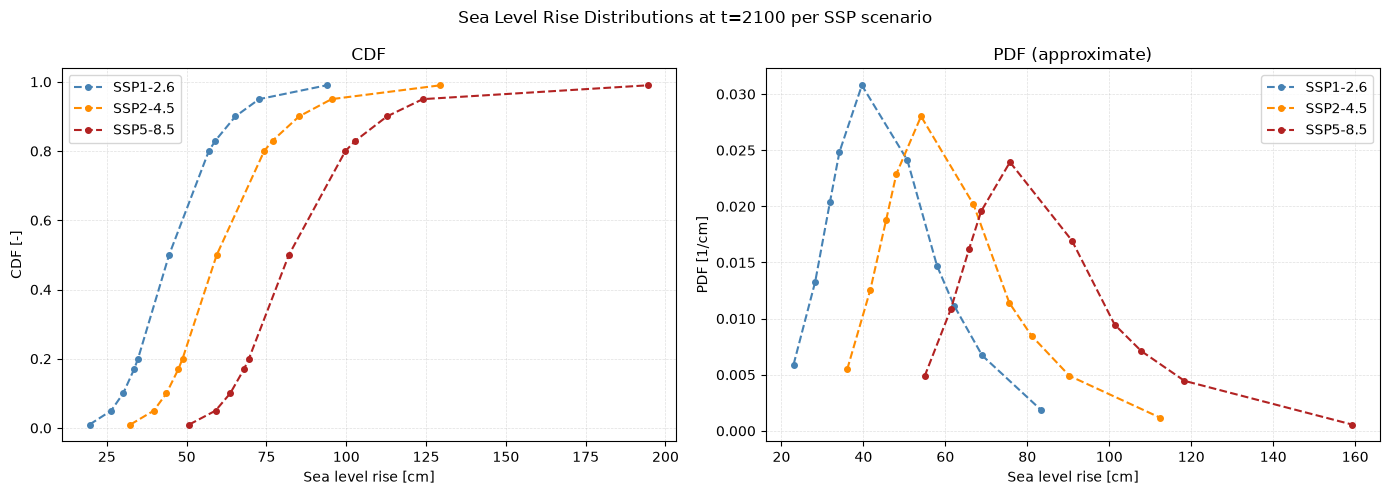

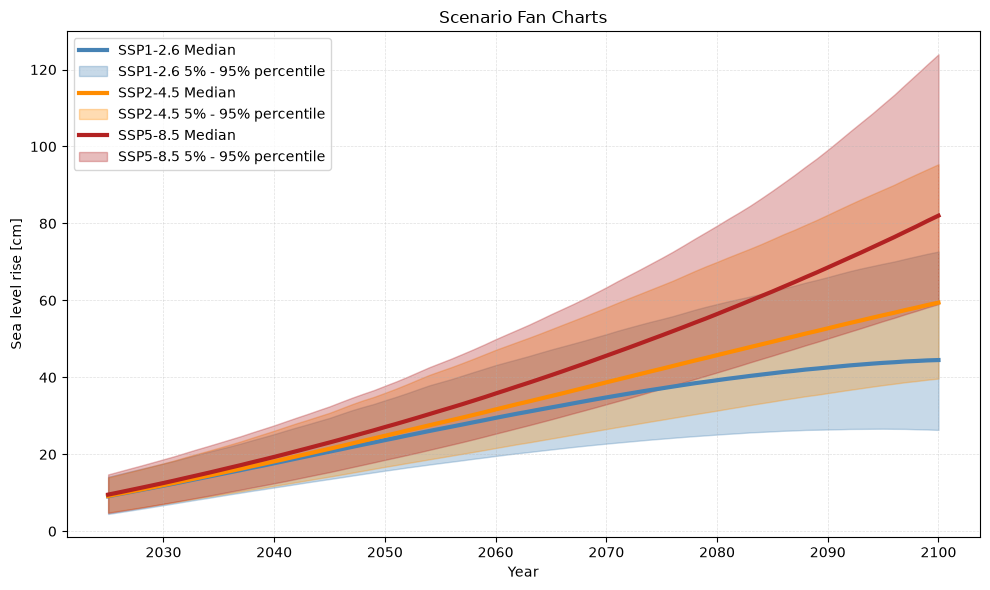

In [3]:
_ = plot_data(2100)
_ = plot_fan_charts(start_year, 2100, extrapolate=False)

## Extrapolation

The quadratic extrapolation is compared with the sparse KNMI values in 2150 and 2300.

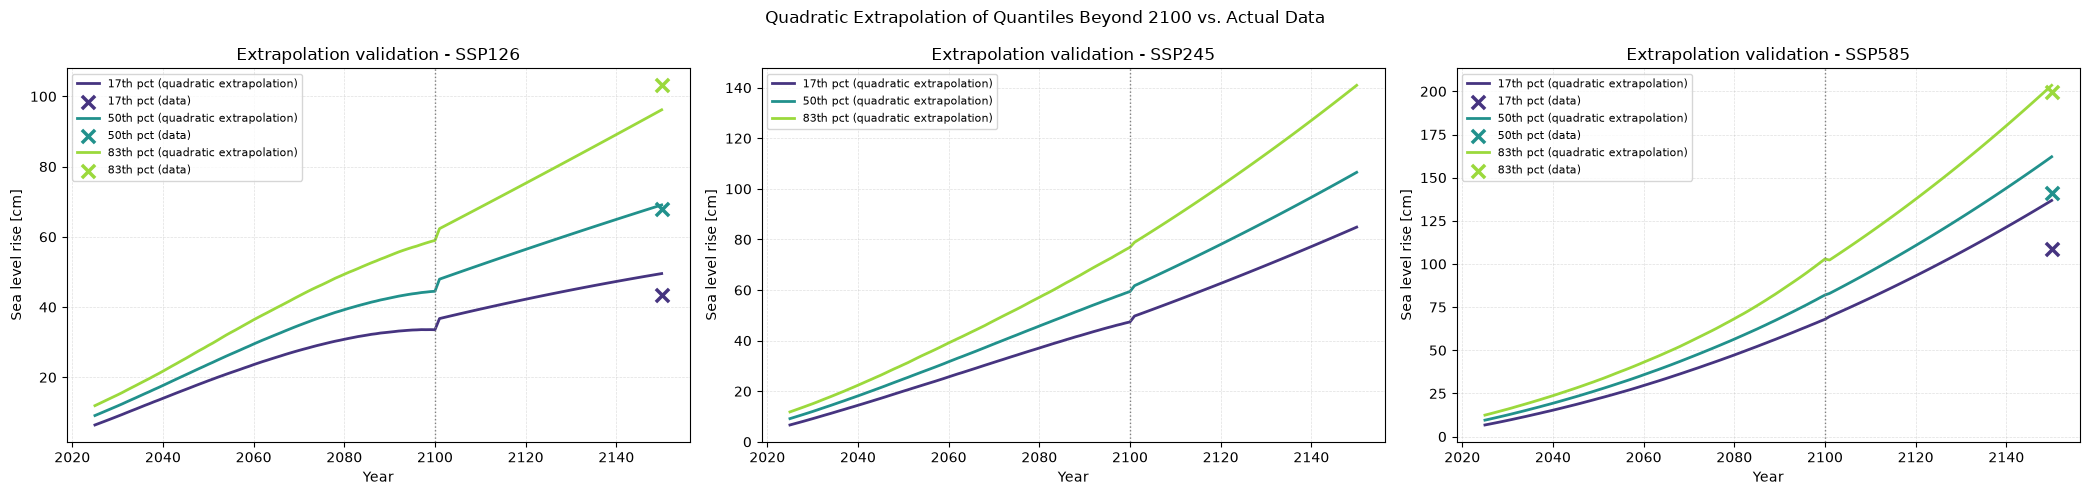

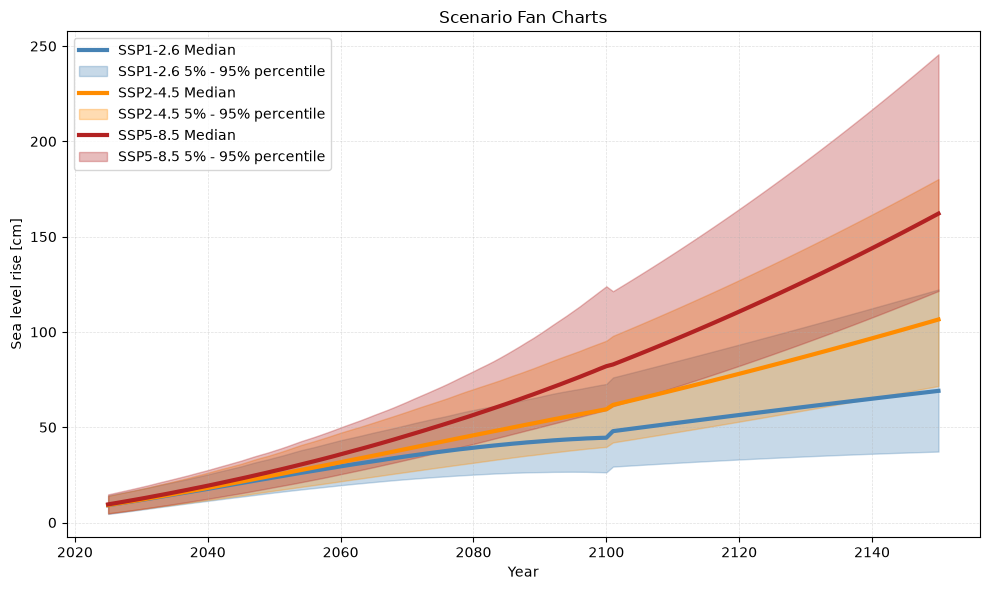

In [4]:
_ = plot_extrapolation_validation(start_year, end_year)
_ = plot_fan_charts(start_year, end_year, extrapolate=True)

## Distribution Fit

Interpolation between the percentiles is exact at the data, but unreliable beyond the outer percentiles. Parametric distributions are therefore fitted by minimizing the mean squared error of the quantiles. Among the candidates, the Pearson type IV distribution is chosen.

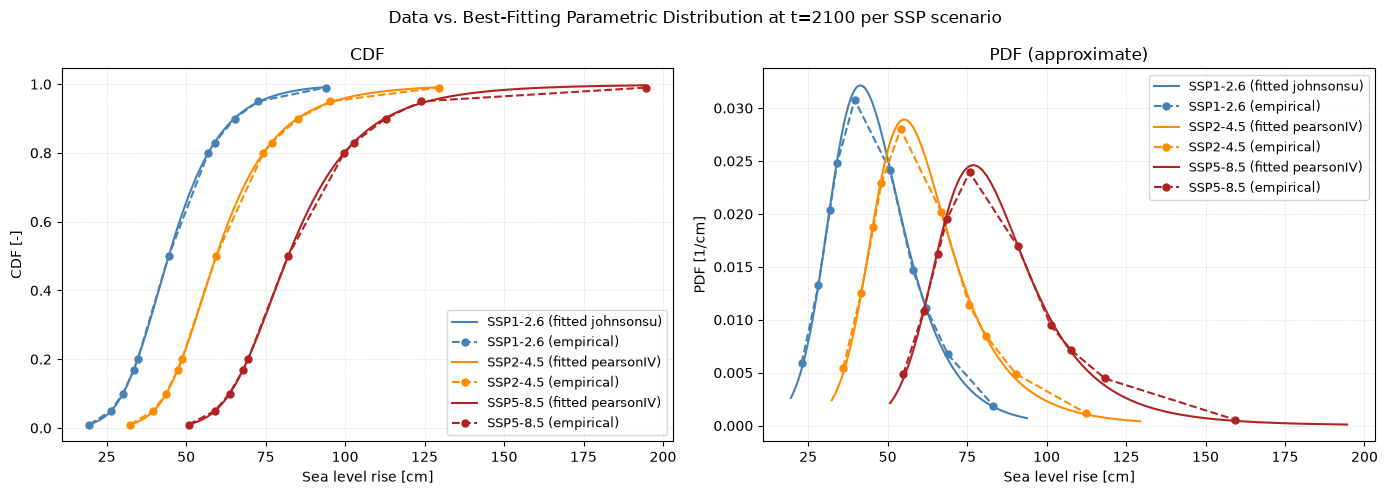

In [ ]:
_ = plot_data_against_best_fitting_distribution(t=2100, extrapolate=True)

## Aggregation

Two methods combine the scenarios into one distribution (adapted from Jongejan et al. 2026):
- **Scenario mixture** (used in the thesis): the weighted mixture of the fitted scenario distributions, $F_t(x) = \sum_s w_s F_{t,s}(x)$.
- **Uncertainty band**: a normal distribution whose 1st and 99th percentile are calibrated to the 5th percentile of SSP1-2.6 and the 95th percentile of SSP5-8.5.

`get_aggregated_quantile_fn` returns the quantile function `fn(t, p)` [m], with `t` in years after its start year.

1st and 99th percentile in 2100: 0.25 m, 1.39 m


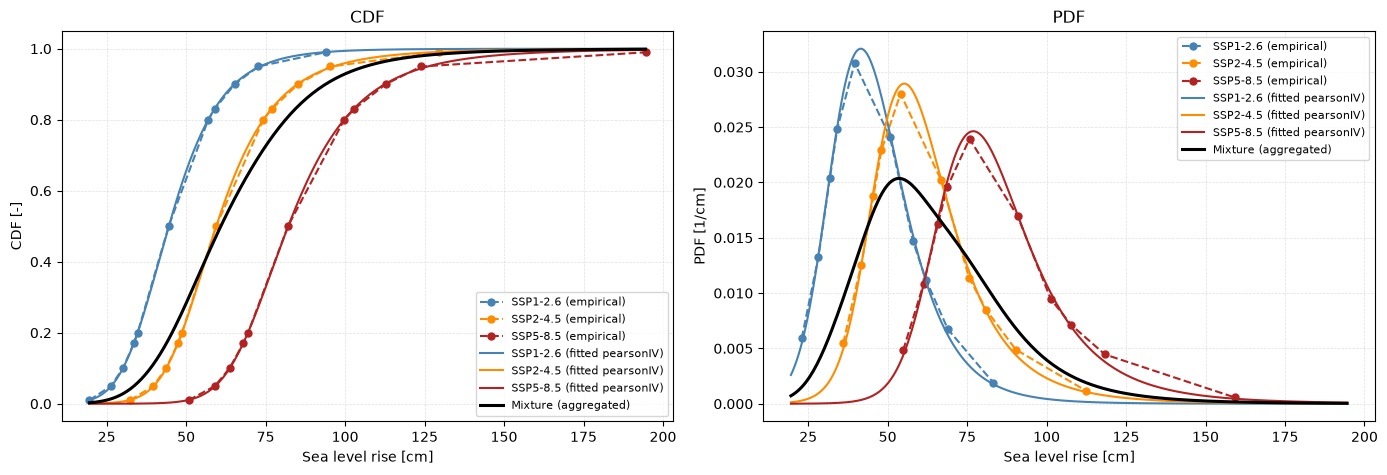

In [6]:
fn, infos = get_aggregated_quantile_fn(
    0, 2300, method="mixture", distribution="pearsonIV", weights=[0.25, 0.5, 0.25], extrapolate=True
)
print(f"1st and 99th percentile in 2100: {fn(2100, 0.01):.2f} m, {fn(2100, 0.99):.2f} m")
_ = plot_aggregated_quantile_fn(t=2100, method="mixture", distribution="pearsonIV", weights=[0.25, 0.5, 0.25], extrapolate=True, title="")